---
---
# TUTORIAL 9: CROSS VALIDATION

---
---

Recently, we've begun building up a toolkit for **predictive modeling**:

| Lecture | Response | Model(s) | How we measured performance |
|---|---|---|---|
| Numeric prediction | Numeric (temperature anomaly) | k-nearest neighbours | Residuals, MSR, MAR |
| Binary classification | Binary (cancer diagnosis) | k-nearest neighbours | Confusion matrix, accuracy, sensitivity, specificity |

**QUESTION:** when we quantified prediction performance, what data did we use to *evaluate* the model?

**ANSWER:** the very same data that we used to *fit* it. Every model was fit to the data, and then judged by how well it reproduced *that same data*.

Today we consider whether that was a good idea. (Spoiler: it wasn't, or at least, it wasn't the *whole* story.) We'll see that evaluating a model on the same data it was fit to can **trick us into thinking the model works much better than it really does**. And we'll learn the standard fix: **cross validation**.


---
---

## Building an Intuition: Practice Tests and Exams

Imagine Nathaniel gives the class a **practice test** to study from. Then, on exam day, Nathaniel hands out **exactly the same questions**.

Two students both get 100%:

* **Student A** has deeply *understood* the course material. They can answer *any* question on the topic.
* **Student B** has *memorized* the answers to the practice test, without understanding why they're right. They can't answer any question they haven't already seen.

Looking only at the exam scores, **you can't tell them apart**. A perfect score on an exam the student has already seen doesn't tell you whether the student has learned the content. To find out who really knows the material, they need to be tested on questions they *haven't seen before*.

**This analogy applies directly to evaluating predictive models:** if you truly want to underatand whether your predictive model is good at predicting, you should evaluate it on data it hasn't seen before.


---
---

## Training Data and Testing Data

We begin by defining some relevant and helpful terminology.

* The data we use to **fit** a model is called the **training data** (or *training set*). The model "studies" it. This is like the practice test.
* The data used to **evaluate** how well the model predicts *new* observations is called the **testing data** (or *test set*). The model has *never seen* it. This is like the exam.

Everything we did in the recent lectures evaluated the models *on the training data*. That's like giving students the practice test as the actual exam. It tells us how well the model *memorized*, not how well it *predicts*.

**The key principle:**

> A predictive model should be tested in the way it's going to be used, on data it hasn't seen.

### The train-test split

The simplest way to do this is a **train-test split**: take the data we have and *randomly set aside* a portion (commonly 20% to 30%) as the testing data. We then:

1. **Fit** the model using *only* the training data.
2. **Evaluate** the model on the testing data, which the model has never seen. The testing performance is our estimate of how the model will perform on genuinely new data.

<div style="text-align: center;">
  <img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/cross-validation.svg" alt="corss_val" width = 150/>
</div>

Let's try it with the global temperature anomaly data from the numeric prediction lectures.

In [46]:
# Load necessary libraries
import pandas as pd
import numpy as np
import plotly.express as px

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

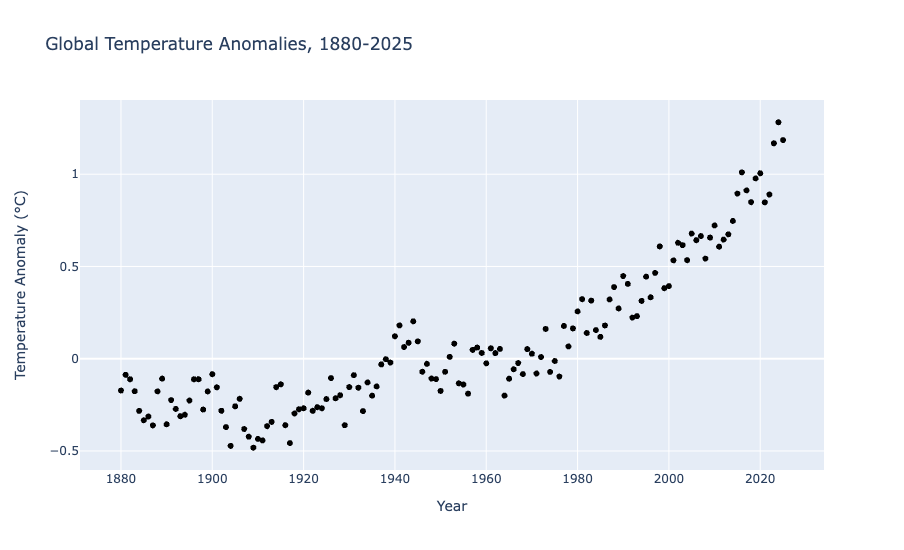

In [47]:
temps = pd.read_csv('https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/data/global_temperature_change.csv')
temps["Year"] = temps["Year"].astype(int)

fig = px.scatter(temps, x = "Year", y = "Temp_Anomaly",
                 title = "Global Temperature Anomalies, 1880-2025",
                 labels = {"Temp_Anomaly": "Temperature Anomaly (°C)"},
                 color_discrete_sequence = ["black"],
                 height = 550)
fig.show()

`scikit-learn` provides `train_test_split()` to do the random split for us. The argument `test_size = 0.3` says that 30% of the observations should go to the testing set. We also set `random_state` to a number of our choosing. (As we did when sampling, this makes the "random" split reproducible, so everyone gets the same one.)

In [48]:
from sklearn.model_selection import train_test_split

X = temps[["Year"]]          # explanatory variable (a data frame)
y = temps["Temp_Anomaly"]    # response variable (a series)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

print("Training set size:", X_train.shape[0])
print("Testing set size: ", X_test.shape[0])

Training set size: 102
Testing set size:  44


We have 102 years for training and 44 years for testing. Let's see which years ended up in which set, and fit a k-NN model with $k = 1$ **using only the training data**:

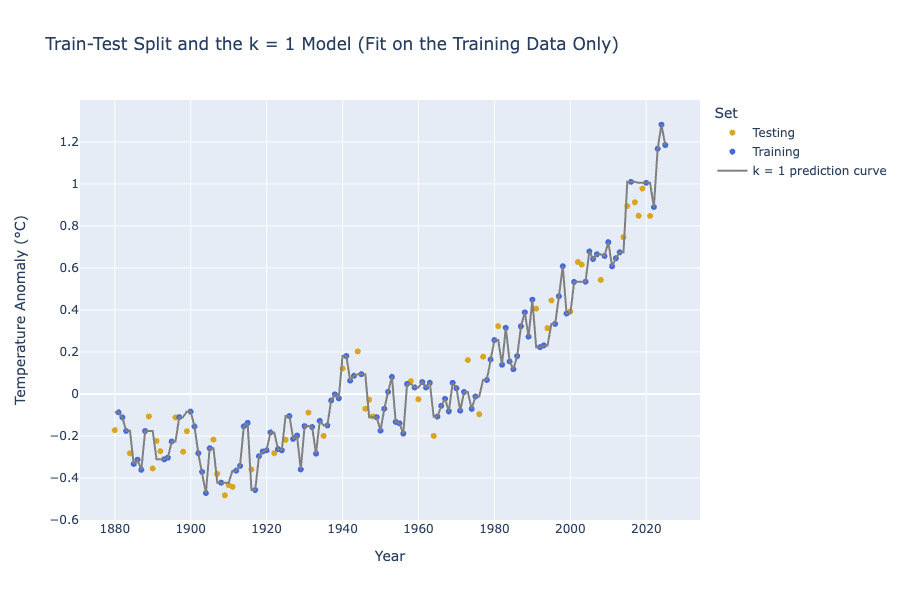

In [49]:
from sklearn.neighbors import KNeighborsRegressor

knn1 = KNeighborsRegressor(n_neighbors = 1)
knn1.fit(X_train, y_train)            # fit using ONLY the training data

year_grid = pd.DataFrame({"Year": np.arange(1880, 2026)})
year_grid["Prediction"] = knn1.predict(year_grid)

split_data = temps.copy()
split_data["Set"] = "Training"
split_data.loc[X_test.index, "Set"] = "Testing"

fig = px.scatter(split_data, x = "Year", y = "Temp_Anomaly", color = "Set",
                 title = "Train-Test Split and the k = 1 Model (Fit on the Training Data Only)",
                 labels = {"Temp_Anomaly": "Temperature Anomaly (°C)"},
                 color_discrete_map = {"Training": "royalblue", "Testing": "goldenrod"},
                 height = 600)

fig.add_scatter(x = year_grid["Year"], y = year_grid["Prediction"], mode = "lines", name = "k = 1 prediction curve",
                line = dict(color = "gray", width = 2))

Looking at the plot, we see:

* The **blue** training points lie *exactly* on the gray prediction curve. The model has memorized them.
* The **gold** testing points, which the model has never seen, are *not* on the curve. The model's predictions for these years miss.

Let's quantify this. In place of the *sum* of squared residuals, we'll return to the **mean squared residual (MSR)** and the **mean absolute residual (MAR)**:

$$\text{MSR} = \frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2 \qquad\qquad \text{MAR} = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat{y}_i|$$

We *average* instead of *sum* because our training set has 102 observations and the testing set has only 44. A sum over 102 residuals would naturally be larger than a sum over 44 even if the model were equally good on both. Averaging puts them on a level playing field.

`scikit-learn` has built-in functions for these in `sklearn.metrics`.

In [50]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

print("Training MSR:", mean_squared_error(y_train, knn1.predict(X_train)))
print("Testing MSR: ", mean_squared_error(y_test, knn1.predict(X_test)))
print("Training MAR:", mean_absolute_error(y_train, knn1.predict(X_train)))
print("Testing MAR: ", mean_absolute_error(y_test, knn1.predict(X_test)))

Training MSR: 0.0
Testing MSR:  0.009879671578283357
Training MAR: 0.0
Testing MAR:  0.08863636363636362


**This is the trick.**

* On the training data, the $k = 1$ model scores a **perfect** MSR and MAR of **0**.
* On the testing data, its MSR is about $0.010$ and its typical miss (MAR) is about $0.09^\circ$C.

If we'd only looked at the training performance, we'd have concluded the model was *perfect*. **Evaluating on the training data can trick us into thinking a model works better than it really does.**

---

#### ACTIVITY 💻: Repeat the above for the k-NN model with $k = 15$. Compute the training and testing MSE and MAE. How does the gap between training and testing performance compare to the $k = 1$ model?

<details>
<summary><b>Show Solution</b></summary>

```python
knn15 = KNeighborsRegressor(n_neighbors = 15).fit(X_train, y_train)

print("Training MSR:", mean_squared_error(y_train, knn15.predict(X_train)))
print("Testing MSR: ", mean_squared_error(y_test, knn15.predict(X_test)))
print("Training MAR:", mean_absolute_error(y_train, knn15.predict(X_train)))
print("Testing MAR: ", mean_absolute_error(y_test, knn15.predict(X_test)))
```

For $k = 15$ the training and testing errors are much closer to each other (the MSRs are about 0.014 and 0.012). The less flexible model doesn't "memorize" the training data, so it has less to gain by looking at training performance alone.

</details>

---
---

## Training vs. Testing Performance for Different Models

Let's compare training and testing performance across a range of values of $k$.

In [53]:
result = []
for k in [1, 2, 3, 5, 10, 15, 20, 30, 50]:
    model = KNeighborsRegressor(n_neighbors = k).fit(X_train, y_train)
    result.append({"k": k,
                 "Training MSR": mean_squared_error(y_train, model.predict(X_train)),
                 "Testing MSR": mean_squared_error(y_test, model.predict(X_test)),
                 "Training MAR": mean_absolute_error(y_train, model.predict(X_train)),
                 "Testing MAR": mean_absolute_error(y_test, model.predict(X_test))})

single_split = pd.DataFrame(result)
single_split.round(4)

,k,Training MSR,Testing MSR,Training MAR,Testing MAR
0,1,0.0000,0.0099,0.0000,0.0886
1,2,0.0033,0.0086,0.0457,0.0805
2,3,0.0042,0.0099,0.0527,0.0844
3,5,0.0067,0.0113,0.0668,0.0911
4,10,0.0106,0.0100,0.0832,0.0874
5,15,0.0140,0.0115,0.0921,0.0919
6,20,0.0178,0.0148,0.0996,0.1029
7,30,0.0265,0.0244,0.1126,0.1230
8,50,0.0541,0.0574,0.1570,0.1730


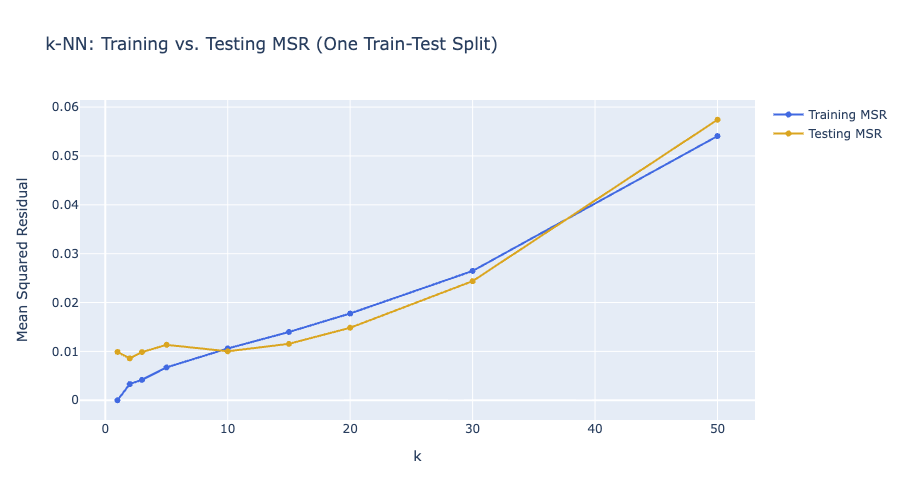

In [68]:
fig = px.line(single_split, x = "k", y = ["Training MSR", "Testing MSR"], markers = True,
              title = "k-NN: Training vs. Testing MSR (One Train-Test Split)",
              labels = {"value": "Mean Squared Residual", "variable": ""},
              color_discrete_sequence = ["royalblue", "goldenrod"],
              height = 500)
fig.show()

**What do we see?**

* **Training MSR increases steadily with $k$.** As we saw in the numeric prediction lecture, the more neighbours we average over, the less closely the model reproduces the training data.
* For the *flexible* models (small $k$), **the testing MSE is clearly larger than the training MSE**. 
* For larger $k$ the two are similar, and (by luck of *this particular split*) the testing MSE is sometimes even a little *smaller* than the training MSE.

That last observation is a warning: a **single** random split is itself *noisy*. If we'd split the data differently we might have seen a different story...


### A single split can mislead

Let's see how much the answer depends on the luck of the split. Below we repeat the $k = 1$ experiment with ten *different* random splits:

In [58]:
result = []
for seed in range(10):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size = 0.3, random_state = seed)
    model = KNeighborsRegressor(n_neighbors = 1).fit(Xtr, ytr)
    result.append({"random_state": seed,
                 "Training MSE": mean_squared_error(ytr, model.predict(Xtr)),
                 "Testing MSE": mean_squared_error(yte, model.predict(Xte))})

pd.DataFrame(result).round(4)

,random_state,Training MSE,Testing MSE
0,0,0.0,0.0090
1,1,0.0,0.0153
2,2,0.0,0.0129
3,3,0.0,0.0082
4,4,0.0,0.0141
5,5,0.0,0.0126
6,6,0.0,0.0136
7,7,0.0,0.0113
8,8,0.0,0.0093
9,9,0.0,0.0166


The training MSE is *always* 0, but the **testing MSE varies from about 0.008 to about 0.017**, depending on which years happened to land in the testing set. Which of these ten numbers is "the" testing error of the $k = 1$ model? None of them and all of them. **A single split gives a noisy estimate.**

The natural remedy: **repeat the split many times and average.** 

### So do many random splits

<div style="text-align: center;">
  <img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/many-cross-validations.svg" alt="corss_val" width = 600/>
</div>

To avoid the noise of a single split, we'll do **200 different random splits** and *average* the results. `scikit-learn`'s `ShuffleSplit` generates these random splits for us.

To see how this process can help us select $k$, we'll repeat the process for many different values of $k$, specifically $k$ from 1 to 60.

*(This takes a few seconds to run.)*

In [62]:
from sklearn.model_selection import ShuffleSplit

splitter = ShuffleSplit(n_splits = 200, test_size = 0.3, random_state = 1)

result = []
for train_index, test_index in splitter.split(X):
    X_tr, X_te = X.iloc[train_index], X.iloc[test_index]
    y_tr, y_te = y.iloc[train_index], y.iloc[test_index]

    for k in range(1, 61):
        model = KNeighborsRegressor(n_neighbors = k).fit(X_tr, y_tr)
        result.append({"k": k, "Model": "k-NN",
                     "Training MSR": mean_squared_error(y_tr, model.predict(X_tr)),
                     "Testing MSR": mean_squared_error(y_te, model.predict(X_te))})

all_splits = pd.DataFrame(result)

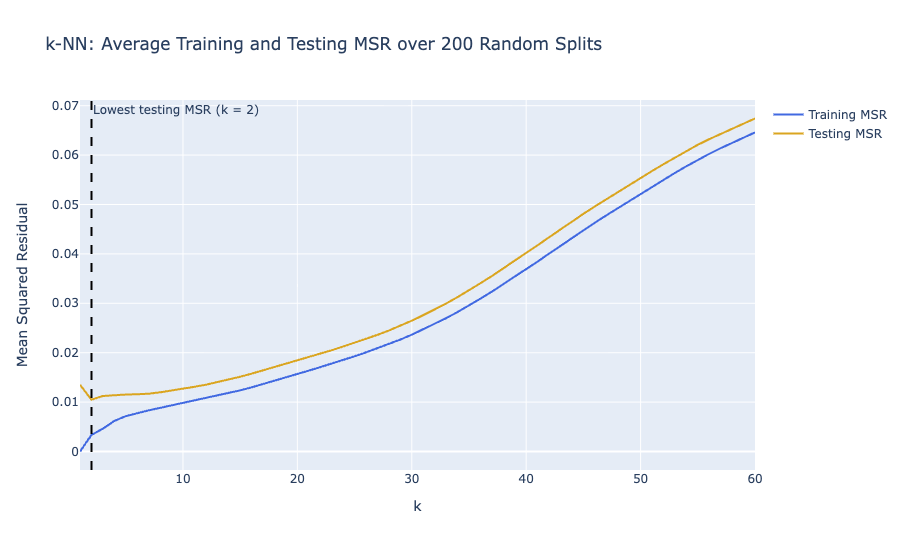

In [67]:
# Average over the 200 splits
knn_curve = all_splits[all_splits["Model"] == "k-NN"].groupby("k")[["Training MSR", "Testing MSR"]].mean().reset_index()

# Plot the MSR curves
fig = px.line(knn_curve, x = "k", y = ["Training MSR", "Testing MSR"],
              title = "k-NN: Average Training and Testing MSR over 200 Random Splits",
              labels = {"value": "Mean Squared Residual", "variable": ""},
              color_discrete_sequence = ["royalblue", "goldenrod"],
              height = 550)

best_k = knn_curve.loc[knn_curve["Testing MSR"].idxmin(), "k"]
fig.add_vline(x = best_k, line_width = 2, line_dash = "dash", line_color = "black",
              annotation_text = f"Lowest testing MSR (k = {int(best_k)})", annotation_position = "top right")

**What do we see?**

* The **training MSR** (blue) starts at zero for $k = 1$ and climbs steadily as $k$ increases: the training data always rewards *more* complexity.
* The **testing MSR** (gold) is *not* at its lowest at $k = 1$, the model with the best training performance. It is higher there (about 0.0135) because the $k = 1$ model *overfits* to the training data. It falls to a minimum at $k = 2$ (about 0.0105), and then climbs steeply as the $k$ increases and the model becomes more rigid.

> **Model selection:** we pick the complexity (here, the value of $k$) with the **lowest testing error**, not the lowest *training* error. Using training error would always choose $k = 1$: the model that memorizes.

A subtle caution: once we've used the testing data to *choose* $k$, the testing error of the chosen model is itself slightly optimistic: we've "peeked". Careful analysts keep a final *untouched* exam, and use it exactly once at the very end. We won't go further here, but it's worth knowing.


---
---

## Cross Validation in Practice

We've seen the key ideas. In practice, data scientists use two standard tools, which both repeat the train-test split many times, so that we aren't misled by the luck of a single split.

### Tool 1: Many random splits

This is what we did above with `ShuffleSplit`: generate many random train-test splits, fit and evaluate on each, and **average the testing errors**. `scikit-learn`'s `cross_val_score()` automates the whole loop. You give it a model, the data, and the type of splitting, and it returns the testing score for each split:

In [70]:
from sklearn.model_selection import cross_val_score

random_splits = ShuffleSplit(n_splits = 100, test_size = 0.3, random_state = 1)

scores = cross_val_score(KNeighborsRegressor(n_neighbors = 5), X, y,
                         cv = random_splits, scoring = "neg_mean_squared_error")

print("Number of splits:", len(scores))
print("First five testing MSRs:", (-scores[:5]).round(4))
print("Average testing MSR:", round(-scores.mean(), 4))

Number of splits: 100
First five testing MSRs: [0.0083 0.011  0.0117 0.0103 0.012 ]
Average testing MSR: 0.0114


> **Why the minus sign?** In `scikit-learn`, *higher scores are always better*. But for errors, *lower* is better. So `scikit-learn` reports the **negative** MSR (`"neg_mean_squared_error"`), so that "higher is better" still holds. We just put a minus sign in front to get back to the usual MSE. (For MAR use `"neg_mean_absolute_error"`.)

### Tool 2: $K$-fold cross validation

**$K$-fold cross validation** is the most common method. (Don't confuse the $K$ of $K$-fold with the $k$ of k-NN. They are unrelated.) It uses *every* observation for testing **exactly once**:

1. **Shuffle** the data and divide it into $K$ equal-sized groups called **folds** (commonly $K = 5$ or $K = 10$).
2. **Round 1:** hold out Fold 1 as the testing set. Fit the model on Folds 2 through $K$. Record the testing error on Fold 1.
3. **Round 2:** hold out Fold 2. Fit on all the other folds. Record the testing error on Fold 2.
4. ... Repeat until every fold has been the testing set once.
5. **Average** the $K$ testing errors. This average is the **cross-validation error**.

Here's what 5-fold cross validation looks like:

| | Fold 1 | Fold 2 | Fold 3 | Fold 4 | Fold 5 |
|:-:|:-:|:-:|:-:|:-:|:-:|
| **Round 1** | 🟧 **test** | 🟦 train | 🟦 train | 🟦 train | 🟦 train |
| **Round 2** | 🟦 train | 🟧 **test** | 🟦 train | 🟦 train | 🟦 train |
| **Round 3** | 🟦 train | 🟦 train | 🟧 **test** | 🟦 train | 🟦 train |
| **Round 4** | 🟦 train | 🟦 train | 🟦 train | 🟧 **test** | 🟦 train |
| **Round 5** | 🟦 train | 🟦 train | 🟦 train | 🟦 train | 🟧 **test** |

Every observation gets used for *both* fitting and testing, but never in the *same* round. This makes efficient use of limited data. In `scikit-learn`, we use `KFold` together with `cross_val_score()`:

In [77]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits = 5, shuffle = True, random_state = 1)

scores = cross_val_score(KNeighborsRegressor(n_neighbors = 5), X, y,
                         cv = kfold, scoring = "neg_mean_squared_error")

fold_errors = pd.DataFrame({"Fold": range(1, 6), "Testing MSR": -scores})
fold_errors.round(4)

,Fold,Testing MSR
0,1,0.0083
1,2,0.0098
2,3,0.0112
3,4,0.0125
4,5,0.0088


In [78]:
print("5-fold cross-validation MSR for k-NN with k = 5:", round(-scores.mean(), 4))

5-fold cross-validation MSR for k-NN with k = 5: 0.0101


Each fold gives a different testing MSE (they range from about 0.008 to 0.013), which shows again how much a single split can vary. Their **average**, about 0.010, is the cross-validation estimate.

(Setting `shuffle = True` randomly shuffles the data before dividing it into folds. This is important when the rows are ordered, as ours are by year, since otherwise Fold 1 would be only the earliest years.)

Now we can compare *any* models on equal terms. Let's compare several values of $k$ and the line:

In [79]:
rows = []
for k in [1, 2, 3, 5, 10, 15, 30]:
    scores = cross_val_score(KNeighborsRegressor(n_neighbors = k), X, y, cv = kfold, scoring = "neg_mean_squared_error")
    rows.append({"Model": f"k-NN (k = {k})", "5-fold CV MSR": -scores.mean()})

pd.DataFrame(rows).round(4)

,Model,5-fold CV MSR
0,k-NN (k = 1),0.0112
1,k-NN (k = 2),0.0079
2,k-NN (k = 3),0.0099
3,k-NN (k = 5),0.0101
4,k-NN (k = 10),0.0115
5,k-NN (k = 15),0.0134
6,k-NN (k = 30),0.0220


### Choosing $k$ automatically: `GridSearchCV`

Comparing models by looping, as above, is so common that `scikit-learn` has a tool that does it for you: `GridSearchCV`. You give it a model, a list of values to try for the complexity knob, and a cross-validation scheme; it runs the cross validation for every value and reports the best.

In [81]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(KNeighborsRegressor(),
                      param_grid = {"n_neighbors": list(range(1, 61))},
                      cv = kfold,
                      scoring = "neg_mean_squared_error")
search.fit(X, y)

print("Best k:", search.best_params_["n_neighbors"])
print("Cross-validation MSR of the best k:", round(-search.best_score_, 4))

Best k: 2
Cross-validation MSR of the best k: 0.0079


5-fold cross validation also selects a small value of $k$, which agrees with our many-random-splits analysis (the exact numbers differ a little because the splits are different).

### Practical advice

| Question | Common practice |
|---|---|
| How many folds? | $K = 5$ or $K = 10$ are the conventional choices. More folds means more training data per round (less pessimistic) but more computing. |
| Many random splits or $K$-fold? | Both are fine. $K$-fold uses each observation for testing exactly once; repeated random splits give you as many repetitions as you like. |
| Always shuffle? | Yes, **unless** the order matters for how the model will be used (e.g., predicting the future from the past), in which case split by time. |
| Which error to report? | The one that matches your goals: MSR or MAR for numeric prediction; accuracy, sensitivity and/or specificity for classification. |
| Is the CV error exact? | No. It's an *estimate*, so treat small differences between models with caution. |


---
---

## Summary of Useful Methods and Functions

| Code | What it does |
|---|---|
| `train_test_split(X, y, test_size = 0.3, random_state = 42)` | Randomly splits the data into training and testing sets. Returns `X_train, X_test, y_train, y_test`. |
| `mean_squared_error(y_true, y_pred)` | Computes the MSR. |
| `mean_absolute_error(y_true, y_pred)` | Computes the MAE. |
| `ShuffleSplit(n_splits = 100, test_size = 0.3, random_state = 1)` | Generates *many random* train-test splits. |
| `KFold(n_splits = 5, shuffle = True, random_state = 1)` | Generates the splits for $K$-fold cross validation. |
| `RepeatedStratifiedKFold(n_splits = 5, n_repeats = 20, random_state = 1)` | Repeated $K$-fold for classification, keeping the class proportions in each fold. |
| `cross_val_score(model, X, y, cv = splitter, scoring = "neg_mean_squared_error")` | Fits and evaluates a model on every split. Returns one (negated) testing score per split. |
| `GridSearchCV(model, param_grid, cv = splitter, scoring = ...)` | Runs cross validation for each value of a complexity knob, and finds the best one. |

---
---

## Key Takeaways

* In the recent lectures, we evaluated every model on **the same data it was fit to**: the **training data**. This **tricks us into thinking the model works better than it really does**, especially for flexible models. (A $k = 1$ model gets a perfect score by memorizing.)
* A predictive model should be **tested in the way it will be used**: on **new data it hasn't seen**. It's the difference between a practice test and an exam with new questions.
* A **train-test split** sets aside a **testing set**. We fit on the **training set** and evaluate on the testing set. We compare performance using the **MSR** or **MAR** (averages, so that sets of different sizes can be compared).
* A **single** random split gives a **noisy** estimate. The remedy is to **repeat** the split many times and average.
* In practice, use **cross validation**: **many random splits** (`ShuffleSplit`) or **$K$-fold cross validation** (`KFold`, usually with $K = 5$ or $10$), run with `cross_val_score()`. 
* This process can be used to choose $k$ (or similar tuning parameters in other models). `GridSearchCV` automates this.
* The same ideas apply to **classification**.

---
---